# Estimadores de CCF sobre un generador con verdad conocida: qué fecha de referencia sesga la EAD

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema (el factor, sus diseños y sus tratamientos)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer los seis niveles de aceleración del generador C09 y decir cuál es su CCF conocido en cada uno;
- explicar las dos agregaciones de un conjunto de factores, la media y la razón agrupada, y por qué difieren cuando las líneas con más monto no utilizado son las que menos usan;
- calcular el sesgo de un estimador contra la verdad conocida con `ccf_bias`, leer `ccf_estimator_bias` (estadístico, valor p, tolerancia y luz) y decir por qué un sesgo significativo dentro de la tolerancia sigue en verde;
- comparar los tres diseños de fecha de referencia y los cuatro tratamientos de un factor fuera de [0, 1] sobre las réplicas versionadas, en cada nivel, y decir cuánto del resultado es propiedad del horizonte propio del generador;
- ajustar los dos modelos de EAD que no necesitan un factor, `fit_direct_ead` y `fit_utilisation_change`, y ver por qué el primero no puede predecir sobre el límite.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import ccf
from riskvalidation.validation import lgd_ead as lgd_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Siete artefactos versionados del caso C09, la exposición al incumplimiento de líneas de crédito rotativas: el artefacto del generador `models-generator.json` y las variantes `level-0.json` a `level-5.json`, una por nivel de aceleración. C09 tiene **una verdad conocida**: sus líneas las produce un generador cuyas distribuciones marginales siguen las carteras hipotéticas de tarjetas de 2025 de la Reserva Federal, y cuyo factor de conversión es un parámetro propio. En el nivel 0 el monto no utilizado se usa a ritmo constante en los doce meses previos al incumplimiento. Desde el nivel 1 el ritmo de uso se acelera en los últimos seis meses por un factor de 1.25 hasta 3, lo que sube el CCF conocido, porque el saldo sube más rápido cerca del incumplimiento.

Cada nivel se evalúa con 20 réplicas de desarrollo y 20 de prueba de 50.000 líneas con semillas fijas, así que cada estimación de los artefactos es la media de 20 réplicas independientes, mostrada con su sesgo contra la verdad, su RMSE y un intervalo de confianza. Los datos son sintéticos y no dicen nada de ningún prestamista. Los artefactos fueron horneados con un motor anterior al instalado, y la celda siguiente imprime ambas versiones.

In [2]:
# Cargar el artefacto del generador y los seis niveles; imprimir los niveles, el plan de réplicas, los diseños y las versiones
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C09"
gen = json.loads((DERIVED / "models-generator.json").read_text(encoding="utf-8"))["fit"]
levels = [json.loads((DERIVED / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
print("horneado con riskvalidation:", sorted({v["provenance"]["riskvalidation_version"] for v in levels}), "| instalado:", rv.__version__)
plan = gen["replications_plan"]
print(f"réplicas: {len(plan['development_seeds'])} desarrollo + {len(plan['test_seeds'])} prueba | líneas por réplica: {plan['n_facilities']:,}")
print()
print(f"{'nivel':>6s} {'factor de aceleración':>26s} {'ventana (meses)':>20s} {'CCF conocido':>14s}")
for lv, doc in zip(gen["levels"], levels):
    print(f"{lv['level']:6d} {lv['acceleration_factor']:26.2f} {lv['acceleration_window_months']:20d} {doc['outputs']['generator']['true_ccf']['value']:14.6f}")
print()
for design in gen["designs"]:
    print("-", design["label"]["es"])
TREAT = {"none": "ninguno", "censor": "censurar", "floor-cap": "piso y tope", "bounded-scale": "escala acotada"}
print("tratamientos:", ", ".join(TREAT[t] for t in gen["treatments"]))

horneado con riskvalidation: ['0.6.0'] | instalado: 0.8.1
réplicas: 20 desarrollo + 20 prueba | líneas por réplica: 50,000

 nivel      factor de aceleración      ventana (meses)   CCF conocido
     0                       1.00                    0       0.600000
     1                       1.25                    6       0.634252
     2                       1.50                    6       0.664272
     3                       2.00                    6       0.714173
     4                       2.50                    6       0.753697
     5                       3.00                    6       0.785540

- Horizonte fijo: 12 meses antes del incumplimiento
- Cohorte anual: el inicio de la cohorte
- Horizonte variable: fechas trimestrales de referencia en el año previo al incumplimiento
tratamientos: ninguno, censurar, piso y tope, escala acotada


## Método

### Paso 1: dos formas de combinar los factores

Dados los factores $c_i$ de $N$ incumplidores y sus montos no utilizados $U_i = L_i - E_i$ en la fecha de referencia, `aggregate_ccf(ccf, undrawn, aggregator)` del motor ofrece dos resúmenes:

$$\text{media} = \frac{1}{N}\sum_i c_i, \qquad \text{agrupado} = \frac{\sum_i c_i\,U_i}{\sum_i U_i} = \frac{\sum_i (EAD_i - E_i)}{\sum_i (L_i - E_i)}$$

(Fuente: el docstring de `aggregate_ccf`; los factores no definidos se excluyen y un conjunto sin ningún factor definido produce un error.) La media da a cada incumplidor el mismo peso; la razón agrupada da el mismo peso a cada unidad de monto no utilizado, así que es la parte de la *moneda* no utilizada que se usó. Las dos difieren cuando el factor depende del tamaño del monto no utilizado. La celda inventa seis incumplidores, tres con poco monto no utilizado que lo usan todo y tres con mucho que usan poco, e imprime ambas.

In [3]:
# Seis incumplidores inventados: montos no utilizados pequeños usados por completo, grandes usados poco; la media y la razón agrupada
factor = np.array([1.0, 1.0, 1.0, 0.2, 0.2, 0.2])
undrawn = np.array([10.0, 10.0, 10.0, 1_000.0, 1_000.0, 1_000.0])
mean_c = ccf.aggregate_ccf(factor, undrawn, "mean")
pooled_c = ccf.aggregate_ccf(factor, undrawn, "pooled")
print(f"media = {mean_c:.4f} | agrupado = {pooled_c:.4f}")
print(f"agrupado a mano: sum(c * U) / sum(U) = {np.sum(factor * undrawn):.1f} / {np.sum(undrawn):.1f} = {np.sum(factor * undrawn) / np.sum(undrawn):.4f}")

media = 0.6000 | agrupado = 0.2079
agrupado a mano: sum(c * U) / sum(U) = 630.0 / 3030.0 = 0.2079


### Paso 2: el sesgo de un estimador y su prueba

Un generador conoce el CCF verdadero, así que un estimador se puede puntuar: `ccf_bias(estimate, truth)` es $\text{estimación} - \text{verdad}$, con signo y sin recorte. C09 repite el experimento $R = 20$ veces y `ccf_estimator_bias(estimates, truth, tolerance)` del motor resume las réplicas. Con $e_r = \hat c_r - c$ el error de la réplica $r$:

$$\text{sesgo} = \bar e, \qquad \text{RMSE} = \sqrt{\overline{e^2}}, \qquad t = \frac{\bar e}{s_e/\sqrt{R}} \; (R - 1 \text{ grados de libertad}), \qquad p = 2\,P(T_{R-1} > |t|)$$

La luz depende solo del sesgo y de una tolerancia, no del valor p: verde cuando $|\text{sesgo}| \le$ tolerancia, ámbar hasta el doble, rojo sobre eso; el valor p es informativo, así que un sesgo estadísticamente significativo dentro de la tolerancia sigue en verde y la vista muestra ambos (todo del docstring de la función, un umbral interno de Contraste y no uno regulatorio). La tolerancia de C09 es 0.02.

La celda siguiente inventa las 20 estimaciones de dos estimadores contra una verdad de 0.6: uno con un sesgo pequeño y estable de -0.015, que es significativo y está dentro de la tolerancia, y uno con un sesgo de -0.05. Esos 40 números son inventados para mostrar cómo se lee la prueba.

In [4]:
# Puntuar dos estimadores inventados contra una verdad conocida de 0.6 con una tolerancia de 0.02
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
rng = np.random.default_rng(11)
truth = 0.6
steady = truth - 0.015 + rng.normal(0.0, 0.004, 20)
poor = truth - 0.05 + rng.normal(0.0, 0.02, 20)
for label, est in (("estable, sesgo -0.015", steady), ("pobre, sesgo -0.05", poor)):
    res = lgd_tests.ccf_estimator_bias(est, truth, tolerance=0.02, model_id=label)
    print(f"{label:34s} sesgo {res.metric:8.4f} (ccf_bias: {ccf.ccf_bias(est.mean(), truth):8.4f}) t={res.statistic:8.3f} p={res.p_value:.2e} RMSE={res.extras['rmse']:.4f} dentro de la tolerancia={si_no(res.extras['within_tolerance'])} luz: {LIGHT[res.light.value]}")

estable, sesgo -0.015              sesgo  -0.0142 (ccf_bias:  -0.0142) t= -19.980 p=3.24e-14 RMSE=0.0145 dentro de la tolerancia=sí luz: verde
pobre, sesgo -0.05                 sesgo  -0.0572 (ccf_bias:  -0.0572) t= -15.166 p=4.54e-12 RMSE=0.0595 dentro de la tolerancia=no luz: rojo


### Paso 3: los sesgos versionados, nivel por nivel

Cada variante por nivel guarda `outputs.ccf_by_design.rows`, 24 filas: tres diseños, cuatro tratamientos y dos agregaciones, cada una con la estimación (la media sobre las 20 réplicas de prueba), el sesgo contra la verdad, el RMSE, el intervalo de confianza y el número de incumplidores usados. La celda selecciona las filas sin tratamiento que más importan: `fixed-horizon` con la media y con la razón agrupada, y `cohort` y `variable-horizon` con ambas agregaciones. Recalcula cada sesgo con `ccf_bias` desde la estimación y la verdad versionadas, e imprime la mayor diferencia contra el sesgo versionado, lo que contrasta el artefacto con la definición del motor.

In [5]:
# Recalcular el sesgo de seis estimadores sin tratamiento en cada nivel con ccf_bias y compararlo con el sesgo versionado
KEYS = [("fixed-horizon", "mean"), ("fixed-horizon", "pooled"), ("cohort", "mean"), ("cohort", "pooled"), ("variable-horizon", "mean"), ("variable-horizon", "pooled")]
DESIGN = {"fixed-horizon": "fijo", "cohort": "cohorte", "variable-horizon": "variable"}
AGG = {"mean": "media", "pooled": "agrupado"}
header = " ".join(f"{DESIGN[d] + ' ' + AGG[a]:>16s}" for d, a in KEYS)
print(f"{'nivel':>5s} {'CCF conocido':>12s} " + header)
biases = {k: [] for k in KEYS}
rmses = {k: [] for k in KEYS}
largest = 0.0
for i, doc in enumerate(levels):
    truth_i = doc["outputs"]["generator"]["true_ccf"]["value"]
    rows = {(r["design"], r["treatment"], r["estimator"]): r for r in doc["outputs"]["ccf_by_design"]["rows"]}
    line = []
    for key in KEYS:
        row = rows[(key[0], "none", key[1])]
        recomputed = ccf.ccf_bias(row["estimate"]["value"], truth_i)
        largest = max(largest, abs(recomputed - row["bias"]))
        biases[key].append(recomputed)
        rmses[key].append(row["rmse"])
        line.append(f"{recomputed:16.4f}")
    print(f"{i:5d} {truth_i:12.4f} " + " ".join(line))
print(f"mayor diferencia entre ccf_bias y el sesgo versionado: {largest:.2e} | tolerancia: {levels[0]['outputs']['ccf_by_design']['tolerance']}")
print()
print("RMSE sobre las 20 réplicas")
for i in range(6):
    print(f"{i:5d} {'':12s} " + " ".join(f"{rmses[key][i]:16.4f}" for key in KEYS))

nivel CCF conocido       fijo media    fijo agrupado    cohorte media cohorte agrupado   variable media variable agrupado
    0       0.6000          -0.0017          -0.0205           0.0823          -0.2579           0.3099          -0.1815
    1       0.6343          -0.0016          -0.0204          -0.1043          -0.2487           0.0032          -0.1729
    2       0.6643          -0.0015          -0.0201          -0.0490          -0.2397           0.4848          -0.1649
    3       0.7142          -0.0014          -0.0193           0.0555          -0.2230           0.0728          -0.1503
    4       0.7537          -0.0013          -0.0183           0.0149          -0.2080           0.1059          -0.1377
    5       0.7855          -0.0011          -0.0173           0.3448          -0.1945           0.2678          -0.1268
mayor diferencia entre ccf_bias y el sesgo versionado: 3.00e-09 | tolerancia: 0.02

RMSE sobre las 20 réplicas
    0                        0.0072      

### Paso 4: la misma tabla, dibujada

La figura dibuja el sesgo de la razón agrupada de los tres diseños contra el nivel de aceleración, con la banda de tolerancia de más y menos 0.02. Usa la razón agrupada porque la tabla de arriba muestra por qué la media no se puede leer en los diseños de cohorte y de horizonte variable: su sesgo salta de un nivel a otro y su RMSE va de 0.1116 a 2.3102 según el nivel, mientras que el de la razón agrupada va de 0.1280 a 0.2583, ya que una razón con un monto no utilizado pequeño en el denominador no está acotada y unas pocas de esas líneas dominan una media sin ponderar. Un diseño dentro de la banda está en verde; un diseño muy por debajo subestima de forma sistemática el CCF conocido.

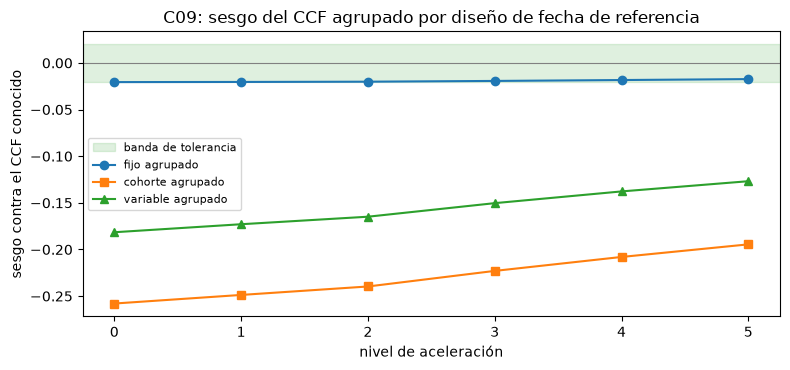

In [6]:
# Dibujar el sesgo de la razón agrupada de los tres diseños contra el nivel de aceleración, con la banda de tolerancia
fig, ax = plt.subplots(figsize=(8, 3.8))
tolerance = levels[0]["outputs"]["ccf_by_design"]["tolerance"]
ax.axhspan(-tolerance, tolerance, color="tab:green", alpha=0.15, label="banda de tolerancia")
for design, marker in (("fixed-horizon", "o"), ("cohort", "s"), ("variable-horizon", "^")):
    ax.plot(range(6), biases[(design, "pooled")], marker=marker, label=f"{DESIGN[design]} agrupado")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("nivel de aceleración")
ax.set_ylabel("sesgo contra el CCF conocido")
ax.set_title("C09: sesgo del CCF agrupado por diseño de fecha de referencia")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Una precaución antes de leer la figura como un ranking. El generador define su CCF conocido sobre los doce meses previos al incumplimiento, que es exactamente el horizonte del diseño `fixed-horizon`. Ese diseño mide, entonces, la cantidad para la que está definida la verdad, y su sesgo casi nulo es en parte por construcción. Los diseños de cohorte y de horizonte variable ponen la fecha de referencia más tarde y miden la parte de un monto no utilizado menor, así que contra esta verdad leen bajo. Lo que muestra la figura es cuán grande es la brecha entre diseños sobre los mismos incumplimientos, no que un diseño sea correcto en general.

### Paso 5: los tratamientos de un factor fuera de [0, 1]

El cuaderno 02 presentó los cuatro tratamientos de `treat_ccf`. Aquí está lo que hace cada uno al sesgo, en el nivel 3, con el diseño de horizonte fijo y ambas agregaciones. `censor` descarta las observaciones fuera de [0, 1], lo que quita las líneas que usaron más que su monto no utilizado y así empuja la estimación hacia abajo; `floor-cap` las recorta, lo que el motor documenta como sesgo de la EAD; `bounded-scale` es la respuesta del logit fraccional sobre los valores recortados. La celda imprime, para cada tratamiento, el número de incumplidores usados, la estimación, el sesgo y si está dentro de la tolerancia.

In [7]:
# Imprimir los cuatro tratamientos del diseño de horizonte fijo en el nivel 3, con ambas agregaciones
doc3 = levels[3]["outputs"]
print("nivel 3, CCF conocido:", doc3["generator"]["true_ccf"]["value"], "|", levels[3]["outputs"]["level_description"]["es"])
print(f"{'tratamiento':18s} {'agregación':>14s} {'incumplidores':>14s} {'estimación':>12s} {'sesgo':>9s} {'dentro de la tolerancia':>26s}")
for r in doc3["ccf_by_design"]["rows"]:
    if r["design"] == "fixed-horizon":
        print(f"{TREAT[r['treatment']]:18s} {AGG[r['estimator']]:>14s} {r['n_defaults']:14,d} {r['estimate']['value']:12.4f} {r['bias']:9.4f} {si_no(r['within_tolerance'])!s:>26s}")
r0 = next(r for r in doc3["ccf_by_design"]["rows"] if r["design"] == "fixed-horizon" and r["treatment"] == "none")
r_censor = next(r for r in doc3["ccf_by_design"]["rows"] if r["design"] == "fixed-horizon" and r["treatment"] == "censor")
print(f"incumplidores descartados al censurar: {r0['n_defaults'] - r_censor['n_defaults']:,}")
print(f"parte de factores bajo 0: {r0['share_below_zero']:.4f} | sobre 1: {r0['share_above_one']:.4f}")

nivel 3, CCF conocido: 0.714173169 | Nivel 3: en los últimos 6 meses previos al incumplimiento el ritmo de uso es 2 veces el anterior.
tratamiento            agregación  incumplidores   estimación     sesgo    dentro de la tolerancia
ninguno                     media         30,154       0.7128   -0.0014                         sí
ninguno                  agrupado         30,154       0.6949   -0.0193                         sí
censurar                    media         25,691       0.6584   -0.0558                         no
censurar                 agrupado         25,691       0.6453   -0.0689                         no
piso y tope                 media         30,154       0.7002   -0.0140                         sí
piso y tope              agrupado         30,154       0.6839   -0.0303                         no
escala acotada              media         30,154       0.7013   -0.0129                         sí
escala acotada           agrupado         30,154       0.6887   -0.0254  

### Paso 6: las pruebas versionadas

`ccf_estimator_bias` del motor corrió sobre las 20 réplicas de cada estimador al hornear, y el artefacto guarda sus filas en `tests`: estadístico, valor p, el sesgo como métrica, el RMSE y el intervalo, la tolerancia y la luz. La celda imprime las filas de cuatro de los estimadores sin tratamiento del paso 3 en el nivel 3 y, para el conjunto de 24 estimadores de ese nivel, cuántos están en verde, ámbar y rojo. Las pruebas las produjo la versión del motor impresa en la sección Datos, así que se leen como se hornearon, sin recalcular.

In [8]:
# Imprimir las filas ccf_estimator_bias versionadas de cuatro estimadores en el nivel 3 y el conteo de luces sobre los 24 estimadores
tests = [t for t in levels[3]["tests"] if t["test_id"] == "lgd_ead.ccf_estimator_bias"]
print("pruebas horneadas con riskvalidation:", levels[3]["provenance"]["riskvalidation_version"], "|", len(tests), "estimadores")
for model_id in ("ccf-fixed-horizon-none-mean", "ccf-fixed-horizon-none-pooled", "ccf-cohort-none-pooled", "ccf-variable-horizon-none-pooled"):
    t = next(t for t in tests if t["model_id"] == model_id)
    print(f"{model_id:34s} sesgo {t['metric']:8.4f}  t={t['statistic']:8.2f}  p={t['p_value']:.2e}  RMSE={t['extras']['rmse']:.4f}  luz: {LIGHT[t['light']]}")
counts = {}
for t in tests:
    counts[t["light"]] = counts.get(t["light"], 0) + 1
print({LIGHT[k]: v for k, v in counts.items()})

pruebas horneadas con riskvalidation: 0.6.0 | 24 estimadores
ccf-fixed-horizon-none-mean        sesgo  -0.0014  t=   -0.85  p=4.07e-01  RMSE=0.0073  luz: verde
ccf-fixed-horizon-none-pooled      sesgo  -0.0193  t=   -5.63  p=1.99e-05  RMSE=0.0244  luz: verde
ccf-cohort-none-pooled             sesgo  -0.2230  t=  -61.65  p=2.38e-23  RMSE=0.2235  luz: rojo
ccf-variable-horizon-none-pooled   sesgo  -0.1503  t=  -39.70  p=9.56e-20  RMSE=0.1512  luz: rojo
{'verde': 4, 'rojo': 18, 'ámbar': 2}


### Paso 7: modelos de EAD sin factor

La investigación pregunta si un modelo de la propia EAD, sin factor, lo hace mejor que el factor (Tong et al. 2016, como lo nombra el docstring del motor). El motor ajusta dos:

- `fit_direct_ead(X, ead, limit)`: un logit fraccional de $EAD / L$ sobre las covariables. Una EAD sobre el límite da una razón sobre 1; se recorta a 1 para el ajuste y se **cuenta** en `extras`, nunca en silencio. El motor anota que la mezcla gamma ajustada en cero de Tong et al. (2016) no está en esta versión.
- `fit_utilisation_change(X, drawn_ref, drawn_default, limit_ref)`: mínimos cuadrados sobre el cambio de utilización $(E(t_d) - E(t_r)) / L(t_r)$, que no tiene monto no utilizado en el denominador.

`predict_ead` devuelve, para el primero, $L$ por la razón ajustada, dentro de $[0, L]$, y para el segundo $E(t_r) + L\,\hat\Delta$, sin recorte. La celda siguiente muestra ambos sobre una muestra **de juguete** generada en el cuaderno (3.000 líneas, un factor conocido de 0.6, un ruido que manda algunas líneas sobre su límite), porque las líneas por préstamo de C09 las genera el pipeline y no se versionan. Imprime los conteos que informa el artefacto versionado para el ajuste real.

In [9]:
# Ajustar los dos modelos de EAD sin factor sobre una muestra de juguete con factor conocido, y leer los conteos del ajuste versionado
rng = np.random.default_rng(7)
n = 3000
limit_toy = np.exp(rng.normal(8.5, 0.8, n))
util = rng.beta(0.8, 1.8, n) * 0.99
drawn_ref = util * limit_toy
ead_toy = drawn_ref + 0.6 * (limit_toy - drawn_ref) + rng.normal(0.0, 0.08, n) * limit_toy
Xe = np.column_stack([np.ones(n), util, np.log(limit_toy)])
cols = ("const", "utilisation", "log_limit")
direct = ccf.fit_direct_ead(Xe, ead_toy, limit_toy, cols)
change = ccf.fit_utilisation_change(Xe, drawn_ref, ead_toy, limit_toy, cols)
pred_direct = ccf.predict_ead(direct, Xe, drawn_ref, limit_toy)
pred_change = ccf.predict_ead(change, Xe, drawn_ref, limit_toy)
print(f"líneas de juguete: {n:,} | EAD realizada sobre el límite: {int((ead_toy > limit_toy).sum())} | recortadas para el ajuste directo (contadas por el motor): {direct.extras['n_clipped_above']}")
print(f"EAD realizada media: {ead_toy.mean():,.1f} | directo: {pred_direct.mean():,.1f} | cambio de utilización: {pred_change.mean():,.1f}")
print(f"predicciones sobre el límite: directo {int((pred_direct > limit_toy).sum())} | cambio de utilización {int((pred_change > limit_toy).sum())} | mayor EAD realizada sobre el límite: {np.max(ead_toy / limit_toy):.3f}")
print()
for m in levels[3]["outputs"]["ead_models"]:
    if m["kind"] in ("direct-ead", "utilisation-change"):
        print(f"ajuste versionado en el nivel 3: {m['model_id']:20s} covariables {m['covariates']} recortadas por abajo {m['n_clipped_below']} recortadas por arriba {m['n_clipped_above']}")

líneas de juguete: 3,000 | EAD realizada sobre el límite: 49 | recortadas para el ajuste directo (contadas por el motor): 49
EAD realizada media: 4,750.4 | directo: 4,746.1 | cambio de utilización: 4,750.9
predicciones sobre el límite: directo 0 | cambio de utilización 0 | mayor EAD realizada sobre el límite: 1.164

ajuste versionado en el nivel 3: direct-ead           covariables ['utilisation', 'log_limit', 'credit_score'] recortadas por abajo 0 recortadas por arriba 12913
ajuste versionado en el nivel 3: utilisation-change   covariables ['utilisation', 'log_limit', 'credit_score'] recortadas por abajo None recortadas por arriba None


## Resultados

- **La verdad se mueve con la aceleración.** El CCF conocido es 0,6000 en el nivel 0 y sube a 0,7855 en el nivel 5, a medida que el ritmo de uso en los últimos seis meses pasa de 1 a 3 veces su ritmo anterior.
- **La media y la razón agrupada son resúmenes distintos.** En los seis incumplidores inventados la media es 0,6000 y la razón agrupada 0,2079 (630,0 sobre 3.030,0), porque las tres líneas con un monto no utilizado grande usan poco.
- **La prueba lee el sesgo, y la luz lee la tolerancia.** En los estimadores inventados, el estable tiene un sesgo de -0,0142, un estadístico t de -19,980 y un valor p de 3,24e-14, y sigue en verde porque está dentro de la tolerancia de 0,02; el pobre, con -0,0572, está en rojo.
- **El diseño fijo de doce meses es casi insesgado, y eso es en parte por construcción.** Su sesgo de la media de factores va de -0,0017 a -0,0011 y su sesgo agrupado de -0,0205 (nivel 0, apenas fuera de la tolerancia de 0,02) a -0,0173. El generador define su CCF sobre esos mismos doce meses.
- **Las fechas de referencia más tardías leen bajo.** El sesgo agrupado del diseño de cohorte es -0,2579 en el nivel 0 y -0,1945 en el nivel 5, y el del diseño de horizonte variable -0,1815 y -0,1268: una fecha de referencia más cercana al incumplimiento mide la parte de un monto no utilizado menor. La brecha se reduce al crecer la aceleración. El sesgo de la media de factores para esos dos diseños es errático (cohorte de -0,1043 a 0,3448, horizonte variable de 0,0032 a 0,4848) y su RMSE llega a 2,3102, de modo que solo la razón agrupada se puede leer.
- **Los tratamientos importan.** En el nivel 3, censurar los factores fuera de [0, 1] lleva el sesgo del horizonte fijo a -0,0558 (media) y -0,0689 (agrupado) y descarta 4.463 de los 30.154 incumplidores; poner piso y tope da -0,0140 y -0,0303, y la escala acotada -0,0129 y -0,0254. Las partes fuera de [0, 1] son 0,0088 bajo 0 y 0,1393 sobre 1.
- **Las pruebas versionadas coinciden.** En el nivel 3, 4 de los 24 estimadores están en verde, 2 en ámbar y 18 en rojo. La razón agrupada del horizonte fijo tiene un valor p de 1,99e-05 y sigue en verde, porque su sesgo de -0,0193 está dentro de la tolerancia; las razones agrupadas de cohorte (t = -61,65) y de horizonte variable están en rojo.
- **Un modelo de EAD directo cuenta lo que recorta.** En la muestra de juguete 49 de 3.000 líneas tienen una EAD realizada sobre su límite (hasta 1,164 veces), el ajuste directo cuenta las mismas 49, y ninguna predicción de ninguno de los dos modelos supera el límite. El ajuste versionado del nivel 3 recortó 12.913 líneas sobre el límite.

Lo que el cuaderno no hace: no dice qué diseño es el correcto para un banco, porque la verdad aquí está definida a doce meses y los datos son sintéticos. La muestra de juguete se genera en el cuaderno solo para mostrar las funciones. El cuaderno siguiente hace el backtest de los modelos de EAD por tramo de utilización.

## Resumen

- Un generador con CCF conocido convierte "¿qué diseño es el correcto?" en una medición: el sesgo de cada estimador contra la verdad, sobre 20 réplicas independientes, con una tolerancia.
- La media y la razón agrupada son resúmenes distintos y dan respuestas distintas cuando las líneas con más monto no utilizado son las que menos usan; la razón agrupada es la parte de la moneda no utilizada que se usó.
- La fecha de referencia es un diseño con un costo: las fechas más tardías leen más bajo contra una verdad definida a doce meses, en una cantidad que se reduce al subir la aceleración. El diseño fijo de doce meses es casi insesgado en parte porque coincide con el horizonte del generador.
- Tratar los factores fuera de [0, 1] mueve la estimación; censurar y recortar la sesgan, y el sesgo se informa, no se esconde.
- Un modelo de EAD directo cuenta las líneas cuya EAD supera el límite y que debe recortar, y no puede predecir sobre el límite; el modelo de cambio de utilización sí puede.

**Qué probar a continuación.** Repite el paso 3 para el tratamiento `censor` y compáralo con `none`; luego sigue con el cuaderno 06, que hace el backtest de los modelos de EAD por tramo de utilización y corre la batería de validación de LGD y EAD.

## Referencias

- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Qi, M. (2009), Exposure at default of unsecured credit cards, OCC Economics Working Paper 2009-2, como se nombra en la documentación del motor de `riskvalidation.lgd_ead.ccf` y `riskvalidation.validation.lgd_ead`.
- BCBS, Basel Framework, CRE32 (enfoque de calificaciones internas; los factores de conversión supervisores). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- La documentación del propio motor de `aggregate_ccf`, `ccf_bias`, `fit_direct_ead`, `fit_utilisation_change`, `predict_ead` y `ccf_estimator_bias` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (caso C09, un generador con verdad conocida) y `data/derived/C09/`.